# 10 Forecasting to 2030

**Rules:** a country series is forecast only if all of these hold:
- The indicator is marked forecastable in the catalogue. That excludes FAO forest area, AQUASTAT water and threatened species counts.
- It has at least 15 consecutive observed annual values, ending within 3 years of that indicator's latest year. No gaps are filled.
- None of those years carries a suspected-interpolation, carried-forward or series-break flag from notebook 01.
- The country is not Sudan or South Sudan (2011 break).

**Models:**
- Random walk with drift, the benchmark.
- Damped-trend exponential smoothing (ETS).
- ARIMA(0,1,1) with drift.

The model for each series is chosen by a rolling-origin backtest: 3 origins, horizons 1 to 3 years, lowest mean absolute error. Every forecast carries 80% and 95% intervals and is saved apart from the observed data. Shares are kept between 0 and 100.

Forecasts extend past trends. They do not model policy changes or shocks.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.dpi": 110, "font.size": 9})
BLUE, GREY, RED, GREEN = "#1f4e79", "#7f7f7f", "#c00000", "#2f6f4f"

DATA = Path("data")
OUT = Path("outputs") / "10 forecasting"
OUT.mkdir(parents=True, exist_ok=True)
for f in OUT.glob("*"):
    f.unlink()          # start each run with an empty outputs folder

obs = pd.read_csv(DATA / "observations.csv", dtype={"flag": str})        # long: iso3, year, indicator_id, value, source, flag
panel = pd.read_csv(DATA / "panel.csv")                # wide: one row per country-year
ind = pd.read_csv(DATA / "indicators.csv").set_index("indicator_id")
cty = pd.read_csv(DATA / "countries.csv").set_index("iso3")
AFRICA = cty.index[cty["group"] == "Africa"].tolist()
name = cty["country_name"].to_dict()
af = obs[obs["iso3"].isin(AFRICA)]
afp = panel[panel["iso3"].isin(AFRICA)]


def label(i):
    return f"{ind.at[i, 'indicator_name']} ({ind.at[i, 'unit']})" if i in ind.index else i


def has(*ids):
    missing = [i for i in ids if i not in panel.columns]
    if missing:
        print("Not in the data, skipped:", ", ".join(missing))
    return not missing


def latest(i, frame=None, max_age=5):
    """Latest observed value per country. Values more than max_age years older than the
    newest year for that indicator are dropped so stale points do not enter rankings."""
    s = (frame if frame is not None else af)
    s = s[s["indicator_id"] == i].sort_values("year").groupby("iso3").tail(1)
    s = s[s["year"] >= s["year"].max() - max_age]
    return s.assign(country=s["iso3"].map(name)).sort_values("value", ascending=False)[["iso3", "country", "year", "value"]]


def change(i, base=(2000, 2002)):
    """Change from the 2000 to 2002 average (damps single-year noise) to the latest value.
    Percentage change only where the base is above the 10th percentile, so tiny bases
    do not produce meaningless growth rates."""
    s = af[af["indicator_id"] == i]
    b = s[s["year"].between(*base)].groupby("iso3")["value"].mean().rename("base")
    l = s.sort_values("year").groupby("iso3").tail(1).set_index("iso3")[["year", "value"]].rename(columns={"value": "latest", "year": "latest_year"})
    d = l.join(b, how="inner")
    d["abs_change"] = d["latest"] - d["base"]
    floor = d["base"].abs().quantile(0.10)
    d["pct_change"] = np.where(d["base"].abs() > floor, 100 * d["abs_change"] / d["base"].abs(), np.nan)
    d.insert(0, "country", d.index.map(name))
    return d.sort_values("abs_change", ascending=False)


def median_path(i, iso=None):
    """Africa median by year (only years where at least 10 countries report), or one economy's series."""
    if iso:
        s = obs[(obs["indicator_id"] == i) & (obs["iso3"] == iso)]
        return s.set_index("year")["value"].sort_index()
    s = af[af["indicator_id"] == i].groupby("year")["value"].agg(["median", "count"])
    return s.loc[s["count"] >= 10, "median"]


def barh(df, value, title, xlabel, path, n=15, color=BLUE):
    d = df.head(n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(d) + 1))
    ax.barh(d["country"], d[value], color=color)
    for y, (v, yr) in enumerate(zip(d[value], d.get("year", d.get("latest_year", [""] * len(d))))):
        ax.text(v, y, f" {v:,.2f} ({yr})" if yr != "" else f" {v:,.2f}", va="center", fontsize=7)
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel); ax.grid(axis="y", visible=False)
    fig.tight_layout(); fig.savefig(OUT / path, dpi=150); plt.show()


def save_excel(path, sheets):
    """Tables to Excel in house style: Tahoma 8, bold headers without fill, frozen header, no gridlines."""
    from openpyxl.styles import Font
    with pd.ExcelWriter(OUT / path, engine="openpyxl") as xl:
        for sheet, frame in sheets.items():
            frame.to_excel(xl, sheet_name=sheet[:31])
        for ws in xl.book.worksheets:
            ws.sheet_view.showGridLines = False
            ws.freeze_panes = "B2"
            for row in ws.iter_rows():
                for c in row:
                    c.font = Font(name="Tahoma", size=8, bold=(c.row == 1))
                    if isinstance(c.value, float):
                        c.number_format = "#,##0.00;(#,##0.00);-"
    return sorted(p.name for p in OUT.iterdir())

In [2]:
import warnings
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

H_END, MIN_OBS = 2030, 15
flags = pd.read_csv(DATA / "quality flags.csv")
bad = flags[flags["flag"].isin(["suspected interpolation", "carried forward", "series break"])].groupby(["indicator_id", "iso3"])["year"].apply(set).to_dict()
fc_ids = set(ind.index[ind.get("forecastable", pd.Series(dtype=str)).eq("Y")])

## 1. Which series qualify?

In [3]:
eligible = []
o = af[af["indicator_id"].isin(fc_ids) & ~af["iso3"].isin(["SDN", "SSD"])]
newest = o.groupby("indicator_id")["year"].max()
for (i, c), g in o.groupby(["indicator_id", "iso3"]):
    s = g.set_index("year")["value"].sort_index()
    gaps = np.where(np.diff(s.index) != 1)[0]
    seg = s.iloc[gaps[-1] + 1:] if len(gaps) else s
    if len(seg) >= MIN_OBS and seg.index.max() >= newest[i] - 3 and not (bad.get((i, c), set()) & set(seg.index)):
        eligible.append((i, c, seg))
print(f"{len(eligible)} country series qualify across {len({e[0] for e in eligible})} indicators")
pd.Series([e[0] for e in eligible]).value_counts().rename("series").to_frame().join(ind["indicator_name"])

531 country series qualify across 11 indicators


,series,indicator_name
A01,52,CO2 emissions excluding LULUCF per capita
A05,52,Total GHG emissions excluding LULUCF
A06,52,Total GHG emissions excluding LULUCF per capita
F01,52,ND-GAIN Country Index score
F02,52,ND-GAIN Vulnerability
F03,52,ND-GAIN Readiness
G07,52,Urban population share
A08,50,Carbon intensity of GDP
D11,48,People using at least basic drinking water
B06,37,Access to electricity


**531 country series across 11 indicators meet the rules.** Forest, water stress and biodiversity series are excluded by design, as are renewable shares for countries with gaps.

## 2. Backtest and forecast

In [4]:
def drift(y, h):
    d = (y[-1] - y[0]) / (len(y) - 1)
    s = np.std(np.diff(y) - d, ddof=1)
    k = np.arange(1, h + 1)
    return y[-1] + d * k, s * np.sqrt(k * (1 + k / (len(y) - 1)))

def ets(y, h):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # small samples often stop short of full convergence; the backtest judges the result
        r = ETSModel(y, error="add", trend="add", damped_trend=True).fit(disp=False)
    f = r.get_prediction(start=len(y), end=len(y) + h - 1).summary_frame(alpha=0.05)
    return f["mean"].to_numpy(), (f["pi_upper"].to_numpy() - f["mean"].to_numpy()) / 1.96

def arima(y, h):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        f = ARIMA(y, order=(0, 1, 1), trend="t").fit().get_forecast(h)
    return f.predicted_mean, np.sqrt(f.var_pred_mean)

MODELS = {"drift": drift, "ets": ets, "arima": arima}

def backtest(y, H=3, origins=3):
    err = {m: [] for m in MODELS}
    for o_ in range(origins, 0, -1):
        tr, te = y[: len(y) - o_ - H + 1], y[len(y) - o_ - H + 1: len(y) - o_ + 1]
        for m, f in MODELS.items():
            try:
                err[m].append(np.mean(np.abs(f(tr, len(te))[0] - te)))
            except Exception:
                pass
    return {m: np.mean(v) if v else np.nan for m, v in err.items()}

rows, evals = [], []
for i, c, seg in eligible:
    y = seg.to_numpy(float)
    mae = backtest(y)
    best = min((m for m in mae if np.isfinite(mae[m])), key=mae.get, default="drift")
    h = H_END - int(seg.index.max())
    if h <= 0:
        continue
    try:
        mean, se = MODELS[best](y, h)
    except Exception:
        best, (mean, se) = "drift", drift(y, h)
    bounded = "%" in str(ind.at[i, "unit"])
    band = {"value": mean, "lower_80": mean - 1.2816 * se, "upper_80": mean + 1.2816 * se, "lower_95": mean - 1.96 * se, "upper_95": mean + 1.96 * se}
    if bounded:
        band = {k_: np.clip(v, 0, 100) for k_, v in band.items()}
    for j, yr in enumerate(range(int(seg.index.max()) + 1, H_END + 1)):
        rows.append({"iso3": c, "indicator_id": i, "year": yr, "model": best, **{k_: v[j] for k_, v in band.items()}})
    evals.append({"indicator_id": i, "iso3": c, "obs": len(y), "last_year": int(seg.index.max()), **{f"mae_{m}": v for m, v in mae.items()},
                  "chosen": best, "skill_vs_drift": 1 - mae[best] / mae["drift"] if mae["drift"] else np.nan})

forecasts, evals = pd.DataFrame(rows), pd.DataFrame(evals)
forecasts.to_csv(DATA / "forecasts.csv", index=False)
print(f"Forecasts for {len(evals)} series. Model chosen:", evals["chosen"].value_counts().to_dict())
print(f"Median skill against drift: {evals['skill_vs_drift'].median():.2f} (0 = no better than drift)")

Forecasts for 531 series. Model chosen: {'arima': 282, 'drift': 249}
Median skill against drift: 0.00 (0 = no better than drift)


**ARIMA was chosen for 282 series and the drift benchmark for 249. Damped ETS never won.** The median skill against drift is 0.00: for half the series, nothing beats extending the recent average trend. Treat the forecasts as trend extrapolations.

## 3. Africa in 2030 on current trends

In [5]:
summary = []
for i in sorted(forecasts["indicator_id"].unique()):
    f = forecasts[(forecasts["indicator_id"] == i) & (forecasts["year"] == H_END)]
    summary.append([i, ind.at[i, "indicator_name"], ind.at[i, "unit"], len(f), median_path(i).iloc[-1] if len(median_path(i)) else np.nan,
                    f["value"].median(), f["lower_80"].median(), f["upper_80"].median()])
summary = pd.DataFrame(summary, columns=["indicator", "name", "unit", "countries", "latest Africa median", "2030 median forecast", "80% low", "80% high"])
summary

,indicator,name,unit,countries,latest Africa median,2030 median forecast,80% low,80% high
0,A01,CO2 emissions excluding LULUCF per capita,t CO2e per capita,52,0.487,0.541,0.334,0.665
1,A05,Total GHG emissions excluding LULUCF,Mt CO2e,52,30.784,31.758,26.948,36.499
2,A06,Total GHG emissions excluding LULUCF per capita,t CO2e per capita,52,1.807,1.616,1.381,1.955
3,A08,Carbon intensity of GDP,kg CO2e per 2021 PPP $ of GDP,50,0.108,0.111,0.065,0.147
4,B06,Access to electricity,% of population,37,60.850,66.945,53.923,75.588
5,B10E,Renewable share of electricity generation,% of electricity generation,32,29.247,27.902,15.359,46.877
6,D11,People using at least basic drinking water,% of population,48,75.295,80.049,79.490,80.650
7,F01,ND-GAIN Country Index score,score (index 0 to 100; components 0 to 1),52,38.376,38.388,36.984,39.484
8,F02,ND-GAIN Vulnerability,score (index 0 to 100; components 0 to 1),52,0.511,0.504,0.494,0.519
9,F03,ND-GAIN Readiness,score (index 0 to 100; components 0 to 1),52,0.281,0.281,0.254,0.309


**On current trends, by 2030 the median African country:**

- emits 0.54 t CO2 per person (from 0.49 t);
- reaches 67% electricity access (from 61%);
- has 80% basic drinking water access (from 75%);
- is 48% urban (from 46%);
- sees little change in ND-GAIN vulnerability (0.50) or readiness (0.28).

The 2030 medians cover only the countries that qualify, so they are not exactly comparable with the all-country latest medians.

## 4. Example: CO2 per capita and renewable share for selected countries

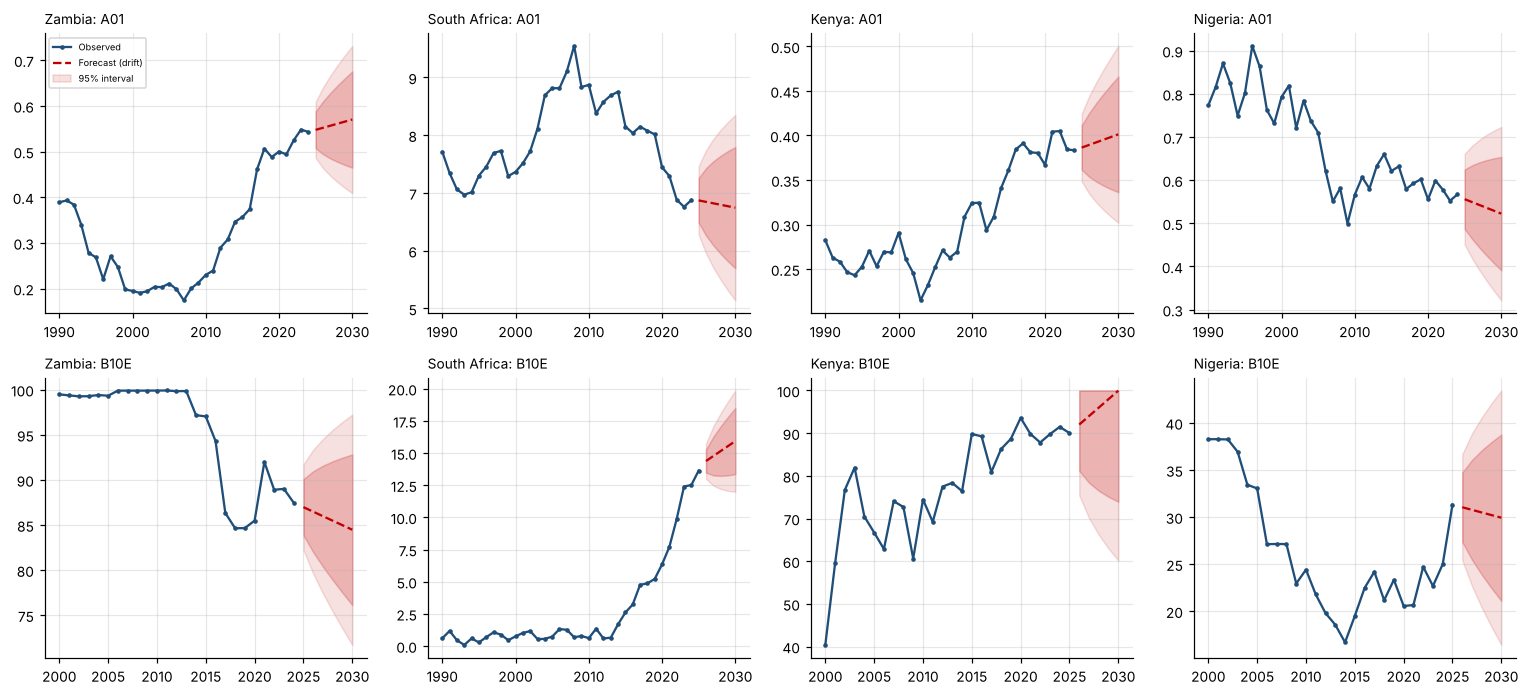

In [6]:
show = [(i, c) for i in ("A01", "B10E") for c in ("ZMB", "ZAF", "KEN", "NGA") if ((forecasts["indicator_id"] == i) & (forecasts["iso3"] == c)).any()]
if show:
    fig, axes = plt.subplots(int(np.ceil(len(show) / 4)), 4, figsize=(14, 3.2 * int(np.ceil(len(show) / 4))), squeeze=False)
    for a, (i, c) in zip(axes.flat, show):
        h = af[(af["indicator_id"] == i) & (af["iso3"] == c)].sort_values("year")
        f = forecasts[(forecasts["indicator_id"] == i) & (forecasts["iso3"] == c)]
        a.plot(h["year"], h["value"], color=BLUE, marker="o", ms=2, label="Observed")
        a.plot(f["year"], f["value"], "--", color=RED, label=f"Forecast ({f['model'].iloc[0]})")
        a.fill_between(f["year"], f["lower_95"], f["upper_95"], color=RED, alpha=0.12, label="95% interval")
        a.fill_between(f["year"], f["lower_80"], f["upper_80"], color=RED, alpha=0.2)
        a.set_title(f"{name.get(c, c)}: {i}", loc="left", fontsize=9)
    axes.flat[0].legend(fontsize=6)
    for a in list(axes.flat)[len(show):]:
        a.axis("off")
    fig.tight_layout(); fig.savefig(OUT / "example forecasts.png", dpi=150); plt.show()

## 5. Save tables

In [7]:
save_excel("forecast results.xlsx", {"2030 summary": summary.set_index("indicator"), "Backtests": evals.set_index("indicator_id"),
                                     "Forecasts": forecasts.set_index("indicator_id")})

['example forecasts.png', 'forecast results.xlsx']

## What I found

- **Trends point to slow change by 2030:** CO2 per person up about 11%, electricity access up about 6 points, water access up about 5 points, and climate readiness flat.
- **The models rarely beat a simple trend** (median skill 0.00), so the intervals matter more than the point forecasts.
- **On current trends, Africa misses SDG 7 universal electricity access by 2030:** the median country reaches about 67%.

**Why it matters for finance:** the access gap in 2030 is an investment gap. Off-grid solar, mini-grids and transmission remain the largest bankable environmental opportunity on the continent.